# Sentiment classification of Polish slang

I compare three methods on the same dataset: a small Transformer trained from random weights, Bielik with LoRA, and Bielik with zero-shot prediction.

In [144]:
from dotenv import load_dotenv
import os

load_dotenv()

hf_token = os.environ.get("HF_TOKEN", None)

I release unused model references and clear the device cache between experiments. This helps limit memory use when I load the next model.

In [145]:
import gc

def free_memory() -> None:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    elif torch.backends.mps.is_available():
        torch.mps.empty_cache()

In [146]:
import random
import numpy as np
import torch

SEED = 42


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


In [147]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [148]:
from time import perf_counter
from matplotlib import pyplot as plt

training_times = {}


def plot_training_history(history, title):
    train_history = [row for row in history if "loss" in row]
    val_history = [row for row in history if "eval_loss" in row]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(
        [row["epoch"] for row in train_history],
        [row["loss"] for row in train_history],
        label="Train loss",
    )
    ax.plot(
        [row["epoch"] for row in val_history],
        [row["eval_loss"] for row in val_history],
        marker="o",
        markersize=4,
        label="Validation loss",
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-entropy loss")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()


# 0. Dataset

I chose `jziebura/polish_youth_slang_classification` to study sentiment in informal Polish text. The examples contain slang, spelling errors, jokes, and references to popular culture. These features can make sentiment less clear than in standard product reviews.

In [149]:
from datasets import load_dataset

ds = load_dataset("jziebura/polish_youth_slang_classification", token=hf_token)
ds = ds.rename_column("sentyment", "labels")
ds = ds.rename_column("tekst", "text")

The labels are `0` for Negative, `1` for Neutral, and `2` for Positive. The tables below show the original rows, class counts, and examples from each class.

In [150]:
ds["train"].to_pandas().head()

,słowo slangowe,znaczenie wyrazów slangowych,źródło,powiązana data,text,labels
0,Furta,Pogardliwe określenie na szerokiego kolegę. Za...,miejski.pl,2024-08-26 20:28:25,"- Masz może lejsy, Damian? - Mam, ale ci nie ...",0
1,rzucać buchem,handlować marihuaną,miejski.pl,2020-07-16 15:36:41,"- Siema mordo, skąd Gucio ma kase na te marko...",1
2,Chędożony,Przymiotnik używany w celu podkreśleniu emocji...,miejski.pl,25.01.2023 13:02,Gówniarz chędożony! Jak nie masz gdzie palcy ...,0
3,Jebnik,"niewyobrażalny brud, syf, bałagan. Synonim sło...",miejski.pl,2025-02-18 14:07:22,- Zaraz wszystko z blatu w kuchni wyląduje w ...,0
4,Baka!,"Po japońsku ""głupek"". Używane (często żartobli...",miejski.pl,13.04.2023 20:16,Baka!,0


In [151]:
classes = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

In [152]:
import pandas as pd
from IPython.display import display
from collections import Counter

split_rows = []
for split, data in ds.items():
    counts = Counter(data["labels"])
    split_rows.append({
        "Split": split,
        "Total": len(data),
        **{name: counts[label] for label, name in classes.items()},
    })
split_summary = pd.DataFrame(split_rows).set_index("Split")
display(split_summary)

examples = (
    ds["train"].to_pandas()
    .groupby("labels", sort=True).head(2)
    .sort_values("labels")[["text", "labels"]]
    .copy()
)
examples["Class"] = examples["labels"].map(classes)
with pd.option_context("display.max_colwidth", None):
    display(examples[["text", "Class"]].reset_index(drop=True))


,Total,Negative,Neutral,Positive
Split,,,,
train,4337,1259,2219,859
validation,542,155,273,114
test,543,148,275,120


,text,Class
0,"- Masz może lejsy, Damian? - Mam, ale ci nie dam, Furto!",Negative
1,Gówniarz chędożony! Jak nie masz gdzie palcy wsadzić to sobie w dupie pogrzeb!,Negative
2,"- Siema mordo, skąd Gucio ma kase na te markowe ubrania? - Rzuca buchem od kilku tygodni.",Neutral
3,"Rano koniecznie jest z cytryną woda, bo wczoraj był lekki melanż",Neutral
4,- I jak poszła randka z Szymonem? - Poszliśmy do niego na Maczkowanie - Zaazdro,Positive
5,Byrgi dowodzi mega content! Uwielbiam!!!,Positive


The histograms compare the class counts in the training and test splits.

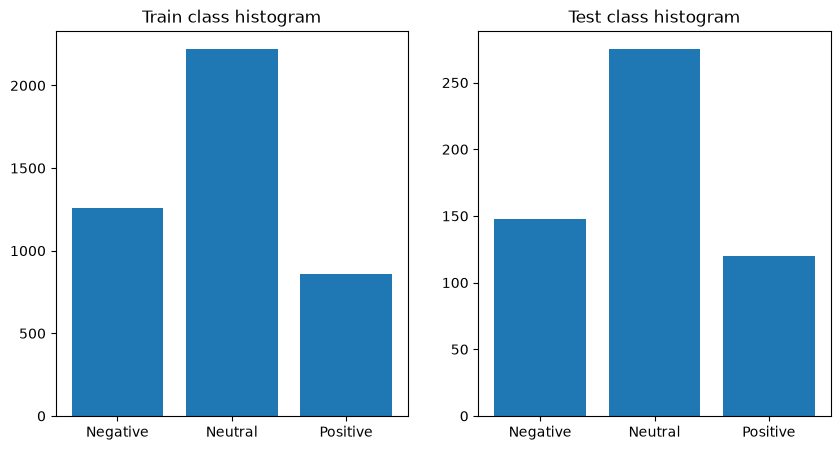

In [153]:
from matplotlib import pyplot as plt
from collections import Counter

fig, axs = plt.subplots(1, 2, figsize=(10, 5))

for ax, name in zip(axs, ["train", "test"]):
    counts = Counter(ds[name]["labels"])
    ax.bar(list(classes.values()), [counts[i] for i in classes])
    ax.set_title(f"{name.capitalize()} class histogram")

plt.show()

Neutral is the largest training class at over 50%. Negative accounts for almost 30%, and Positive accounts for about 20%.

I rate the models on both accuracy and macro F1 metrics because of the imbalanced class distribution.

# 1. Custom model

I first trained a small Transformer from random weights. This experiment tests what the model can learn from the labelled dataset alone. I did not pretrain it to predict the next token.

I used a GPT-style architecture with causal attention and a classification head. I placed a `[CLS]` token at the end of each text so it can use information from the whole text.

I train a byte-level BPE tokenizer only on the training texts, with a target vocabulary size of 8,000. 
I add `[PAD]`, `[CLS]`, and `[UNK]` as special tokens. The tokenizer appends `[CLS]` after the text. `DataCollatorWithPadding` pads each batch to the length of its longest sequence.

In [154]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

SPECIAL_TOKENS = ["[PAD]", "[CLS]", "[UNK]"]

PAD = 0
CLS = 1
VOCAB_SIZE = 8000


def train_tokenizer(sequences: list[str], vocab_size: int) -> Tokenizer:
    tokenizer = Tokenizer(models.BPE(unk_token="[UNK]"))

    tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel()
    tokenizer.decoder = decoders.ByteLevel()

    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        special_tokens=SPECIAL_TOKENS,
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
        show_progress=False
    )

    tokenizer.train_from_iterator(sequences, trainer=trainer)
    return tokenizer

In [155]:
from tokenizers.processors import TemplateProcessing
from transformers import PreTrainedTokenizerFast

set_seed(SEED)

raw_tokenizer = train_tokenizer(ds["train"]["text"], VOCAB_SIZE)

raw_tokenizer.post_processor = TemplateProcessing(
    single="$A [CLS]",
    special_tokens=[("[CLS]", raw_tokenizer.token_to_id("[CLS]"))],
)

tokenizer_scratch = PreTrainedTokenizerFast(
    tokenizer_object=raw_tokenizer,
    pad_token="[PAD]",
    cls_token="[CLS]",
    unk_token="[UNK]",
    padding_side="right",
    model_input_names=["input_ids", "attention_mask"],
)

In [156]:
def tokenize(tokenizer, batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128,
    )

In [157]:
from transformers import DataCollatorWithPadding

tokenized_scratch = ds.map(
    lambda x: tokenize(tokenizer_scratch, x),
    batched=True)

collator_scratch = DataCollatorWithPadding(tokenizer=tokenizer_scratch)

The histograms show sequence lengths after tokenization and truncation. They describe the input that the model receives, rather than the original text lengths.

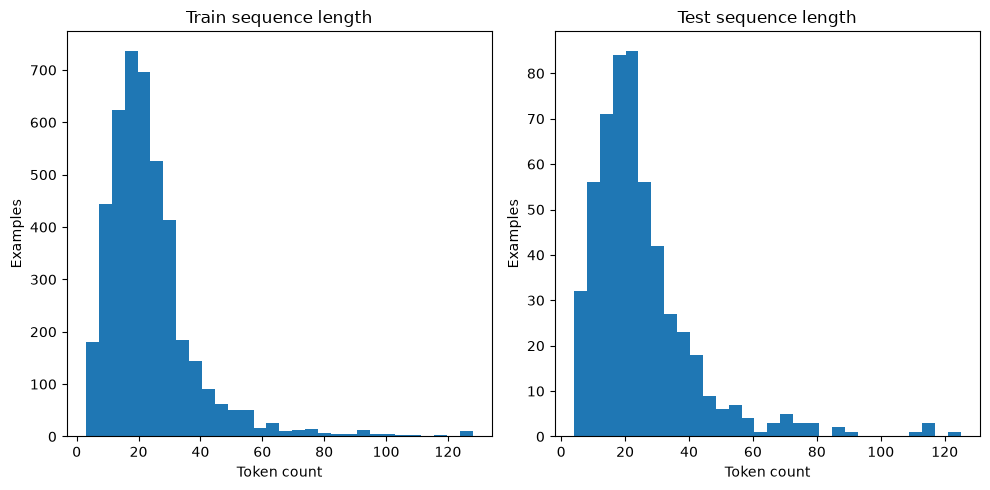

In [158]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

for ax, split, name in zip(
    axs,
    ["train", "test"],
    ["Train", "Test"],
):
    lengths = [len(ids) for ids in tokenized_scratch[split]["input_ids"]]

    ax.hist(lengths, bins=30)
    ax.set_title(f"{name} sequence length")
    ax.set_xlabel("Token count")
    ax.set_ylabel("Examples")

plt.tight_layout()
plt.show()

I have displayed those histograms for different max `BLOCK_SIZE` values to check how much of the text gets truncated. I have decided to stick with `128` as it didn't truncate almost any texts.

The model converts each input token into a learned embedding. Three Transformer blocks then process the sequence. Each block contains layer normalization, causal attention, a feed-forward network, residual connections, and dropout.

I used rotary position embeddings (RoPE) to reduce the number of trainable parameters. RoPE rotates the query and key vectors according to their token positions. It uses fixed frequencies and adds no trainable parameters. I removed the learned position embedding table. For 128 positions and 64 embedding dimensions, this removes 8,192 parameters compared with the same model using that table.

The classifier uses the final non-padding token, which is the appended `[CLS]` token. A linear layer converts its representation into three logits. Logits are raw scores for the three sentiment classes. During training, `F.cross_entropy(logits, labels)` compares these scores with the true labels.

| Setting | Value |
|---|---:|
| Transformer blocks | 3 |
| Embedding dimension | 64 |
| Attention heads per block | 4 |
| Feed-forward hidden dimension | 4 |
| Position encoding | RoPE |
| Maximum input length | 128 tokens |
| Dropout | 0.2 |
| Total parameters | About 0.6 million |

In [159]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Rotary Positional Embedding (RoPE) function
# Applies a rotation to each pair of dimensions in the input tensor based on position and frequency
# 
# It provides a way to encode positional information into the input tensor without adding explicit positional embeddings.
def apply_rope(x, start_pos = 0, base = 10000.0):
    N, H, T, D = x.shape

    # we divide the vector x into pairs 
    # q = [(q0, q1), (q2, q3), (q4, q5), ..., (q62, q63)]
    #
    positions = torch.arange(
        start_pos, start_pos + T,
        device=x.device,
        dtype=torch.float32
    )

    #
    # We want to "rotate" each pair with the corresponding angle
    # 
    freqs = base ** (
        -torch.arange(
            0, D, 2,
            device=x.device,
            dtype=torch.float32
        ) / D
    )

    angles = positions[:, None] * freqs[None, :]

    cos = angles.cos()[None, None, :, :]
    sin = angles.sin()[None, None, :, :]

    x_even = x[..., ::2]
    x_odd = x[..., 1::2]

    # we apply the rotation formula for vectors in each pair
    # 
    # x' = x * cos(theta) - y * sin(theta)
    # y' = x * sin(theta) + y * cos(theta)
    # 
    rotated = torch.stack(
        (
            x_even * cos - x_odd * sin,
            x_even * sin + x_odd * cos
        ),
        dim=-1
    )

    return rotated.flatten(-2).to(x.dtype)

class MultiHeadAttention(nn.Module):
    def __init__(self, dim, num_heads):
        super().__init__()
        assert dim % num_heads == 0

        self.num_heads = num_heads
        self.head_dim = dim // num_heads

        self.qkv = nn.Linear(dim, 3 * dim, bias=False)
        self.proj = nn.Linear(dim, dim, bias=False)

    def forward(self, x):
        B, T, C = x.shape

        q, k, v = self.qkv(x).chunk(3, dim=-1)

        q = q.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)

        q = apply_rope(q)
        k = apply_rope(k)

        out = F.scaled_dot_product_attention(
            q, k, v,
            is_causal=True
        )

        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.proj(out)


class MLP(nn.Module):
    def __init__(self, dim, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, dim),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, dim, num_heads, ff_hidden_dim, dropout):
        super().__init__()

        self.norm1 = nn.LayerNorm(dim)
        self.attn = MultiHeadAttention(dim, num_heads)

        self.norm2 = nn.LayerNorm(dim)
        self.mlp = MLP(dim, ff_hidden_dim)
        self.dropout = nn.Dropout(dropout)


    def forward(self, x):
        x = x + self.dropout(self.attn(self.norm1(x)))
        x = x + self.dropout(self.mlp(self.norm2(x)))
        return x


class SentimentClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        num_classes,
        dim,
        num_heads,
        ff_hidden_dim,
        num_layers,
        block_size,
        dropout=0.2,
    ):
        super().__init__()

        self.block_size = block_size

        self.token_embedding = nn.Embedding(vocab_size, dim)
        # self.position_embedding = nn.Embedding(block_size, dim)

        self.blocks = nn.Sequential(*[
            TransformerBlock(dim, num_heads, ff_hidden_dim, dropout)
            for _ in range(num_layers)
        ])

        self.norm = nn.LayerNorm(dim)
        self.classifier = nn.Linear(dim, num_classes)

    def forward(self, input_ids, attention_mask=None, labels=None):
        B, T = input_ids.shape
        assert T <= self.block_size

        positions = torch.arange(T, device=input_ids.device)

        x = self.token_embedding(input_ids)

        x = self.blocks(x)
        x = self.norm(x)

        # last token has attended with whole sentence
        # so we chose his representation
        last = (input_ids != PAD).sum(dim=1) - 1
        x = x[torch.arange(B, device=input_ids.device), last]

        logits = self.classifier(x)

        # syntax expected by transformers.Trainer
        output = {"logits": logits}

        if labels is not None:
            output["loss"] = F.cross_entropy(logits, labels)

        return output

In [160]:
BLOCK_SIZE = 128

model_scratch = SentimentClassifier(
    vocab_size=len(tokenizer_scratch),
    num_classes=3,
    dim=64,
    num_heads=4,
    ff_hidden_dim=4,
    num_layers=3,
    block_size=BLOCK_SIZE,
    dropout=0.2
)

params = sum(p.numel() for p in model_scratch.parameters())
print(f"Parameters: {params / 1_000_000:.1f}M")

Parameters: 0.6M


I chose small batch size of 16 for training for implicit regularization, I tried to avoid overfitting, but with such small dataset it was almost impossible.

The Trainer evaluates and saves a checkpoint after each epoch. It selects the checkpoint with the highest validation macro F1.

In [161]:
from sklearn.metrics import f1_score, accuracy_score
import numpy as np
from transformers import Trainer, TrainingArguments

BATCH_SIZE = 16
EPOCHS = 15
LR = 1e-4


def compute_metrics(pred):
    y_pred = np.argmax(pred.predictions, axis=-1)
    y_true = pred.label_ids

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1": f1_score(
            y_true,
            y_pred,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
    }

args_scratch = TrainingArguments(
    output_dir="./custom_sentiment",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=LR,
    optim="adamw_torch",
    weight_decay=0.1,

    max_grad_norm=1.0,
    warmup_steps=0.05,
    lr_scheduler_type="constant_with_warmup",

    eval_strategy="epoch",
    logging_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    seed=SEED,
    report_to="none",
    disable_tqdm=False,
)

trainer_scratch = Trainer(
    model=model_scratch,
    args=args_scratch,
    train_dataset=tokenized_scratch["train"],
    eval_dataset=tokenized_scratch["validation"],
    processing_class=tokenizer_scratch,
    data_collator=collator_scratch,
    compute_metrics=compute_metrics,
)

train_result_scratch = trainer_scratch.train()
training_times["Scratch"] = {
    "training_total_s": train_result_scratch.metrics["train_runtime"],
    "epochs": trainer_scratch.state.epoch,
    "training_mean_epoch_s": (
        train_result_scratch.metrics["train_runtime"] / trainer_scratch.state.epoch
    ),
}
print("Best scratch checkpoint:", trainer_scratch.state.best_model_checkpoint)

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,1.084902,1.011837,0.503690,0.223313
2,0.988664,0.974992,0.525830,0.339016
3,0.962483,0.953994,0.544280,0.373804
4,0.938967,0.950468,0.544280,0.396549
5,0.920171,0.944890,0.535055,0.424217
6,0.900372,0.942556,0.533210,0.429874
7,0.879719,0.944541,0.535055,0.430915
8,0.857634,0.947774,0.547970,0.432790
9,0.833170,0.959663,0.553506,0.443455
10,0.808802,0.957852,0.546125,0.468530


Best scratch checkpoint: ./custom_sentiment/checkpoint-3264


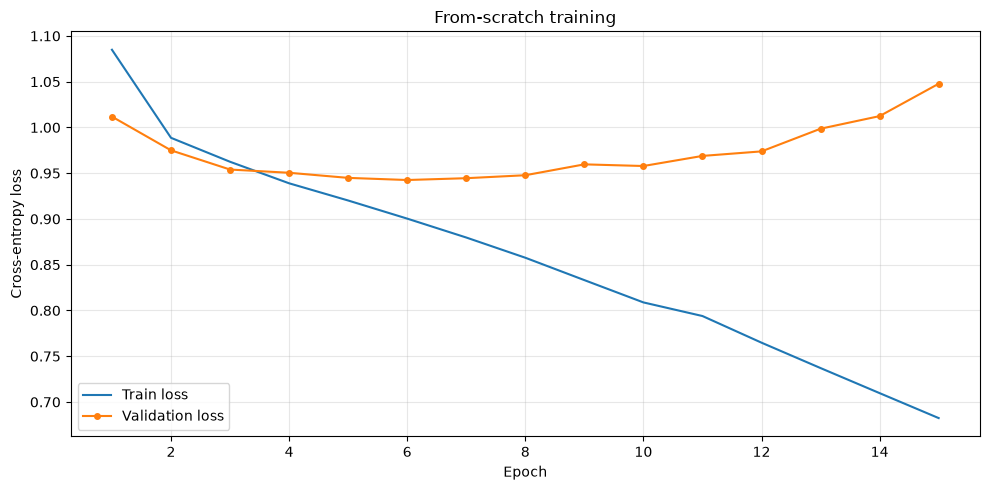

In [162]:
history_scratch = trainer_scratch.state.log_history
plot_training_history(history_scratch, "From-scratch training")


We can see that the training loss is still decreasing, but the validation loss has started to increase. Interestingly we can still observe some improvements to validation F1 score. This might indicate that the model is becoming more confident in its wrong predictions while still changing probabilities improving TP/FP ratios for other examples. This means that we are observing extreme overfitting to test data.

In [163]:
from datasets import Dataset
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

INFERENCE_BATCH_SIZE = 8


def test_model(trainer, data, batch_size=INFERENCE_BATCH_SIZE):
    trainer.args.per_device_eval_batch_size = batch_size
    model_device = trainer.args.device
    texts = list(data["text"])

    if model_device.type == "cuda":
        torch.cuda.synchronize(model_device)
    start = perf_counter()
    # Encode raw texts on every call; no cached tokenized dataset is used.
    encoded = tokenize(trainer.processing_class, {"text": texts})
    result = trainer.predict(Dataset.from_dict(encoded))
    if model_device.type == "cuda":
        torch.cuda.synchronize(model_device)
    inference_time = perf_counter() - start

    # Labels and quality metrics stay outside the encoding + inference timer.
    y_true = np.asarray(data["labels"])
    y_pred = result.predictions.argmax(axis=-1)
    probabilities = torch.softmax(
        torch.from_numpy(result.predictions).float(), dim=-1
    ).numpy()
    loss = F.cross_entropy(
        torch.from_numpy(result.predictions).float(),
        torch.from_numpy(y_true).long(),
    ).item()

    metrics = {
        "loss": loss,
        "probabilities": probabilities,
        "probability_class_ids": [0, 1, 2],
        "predictions": y_pred,
        "predicted_classes": [classes[label] for label in y_pred],
        "inference_time_seconds": inference_time,
        "inference_samples_per_second": len(data) / inference_time,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
        "confusion_matrix": confusion_matrix(
            y_true, y_pred, labels=[0, 1, 2]
        ),
    }

    print(f"Test loss:     {metrics['loss']:.4f}")
    print(f"Test accuracy: {metrics['accuracy']:.2%}")
    print(f"Test macro F1: {metrics['macro_f1']:.4f}")
    print(f"Test encoding + inference time: {metrics['inference_time_seconds']:.3f} s")
    print(f"Test throughput: {metrics['inference_samples_per_second']:.1f} examples/s")

    ConfusionMatrixDisplay(
        confusion_matrix=metrics["confusion_matrix"],
        display_labels=[classes[i] for i in [0, 1, 2]],
    ).plot(cmap="Blues", values_format="d")
    plt.tight_layout()
    plt.show()

    return metrics


Test loss:     0.9736
Test accuracy: 53.96%
Test macro F1: 0.4839
Test encoding + inference time: 0.216 s
Test throughput: 2513.2 examples/s


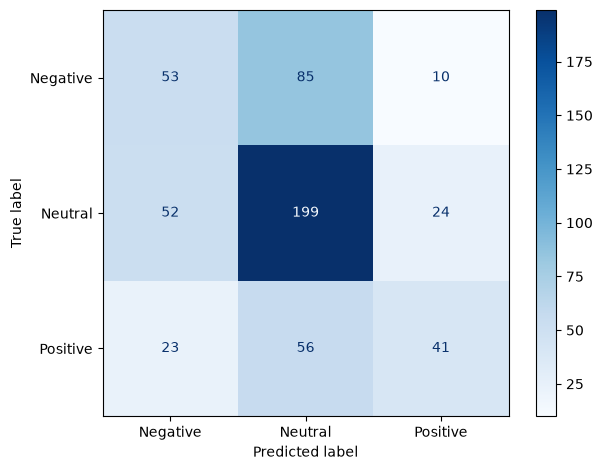

In [164]:
scratch_results = test_model(trainer_scratch, ds["test"])


### Example predictions

In [165]:
example_predictions = pd.DataFrame(
    scratch_results["probabilities"][:6],
    columns=[classes[label] for label in scratch_results["probability_class_ids"]],
)
example_predictions.insert(0, "Text", list(ds["test"]["text"][:6]))
example_predictions.insert(1, "True class", [classes[label] for label in ds["test"]["labels"][:6]])
example_predictions.insert(2, "Predicted class", scratch_results["predicted_classes"][:6])
with pd.option_context("display.max_colwidth", None):
    display(example_predictions.round(2))


,Text,True class,Predicted class,Negative,Neutral,Positive
0,"-Wiedziałeś o tym, że Chopin odkrył poruszanie się słońca wokół Ziemii? -Co to za sritititi.",Negative,Neutral,0.37,0.43,0.19
1,- masz malego - twój stary,Negative,Positive,0.04,0.41,0.55
2,"- Jesteś Sigma ? - Nie, jestem Ypsilon.",Neutral,Neutral,0.25,0.63,0.12
3,"- Mordo ale śmierdzisz -Ta, właśnie idę zwodować jajo",Neutral,Neutral,0.16,0.80,0.05
4,"Ludzie którzy nie rozumieją contentu Marcel to albo debile, albo boomerzy.",Negative,Negative,0.52,0.43,0.06
5,"U mnie w podstawówce to palarnia była dosłownie przy drugim wejściu do szkoły, nauczyciele widzieli, nic sobie z tego nie robili (patola straszna).",Negative,Negative,0.53,0.35,0.13


In [166]:
del trainer_scratch, model_scratch
del collator_scratch, tokenized_scratch, tokenizer_scratch, raw_tokenizer
free_memory()

The test result is 55% accuracy and 0.49 F1. Accuracy remains close to the 51% naive baseline (predicting only Neutral class). Macro F1 exceeds the baseline score of about 0.22, which shows that the model didn't completely exploit class imbalance.

I rate those results as not as terrible - we have managed to beat the naive baseline! I believe that pretraining the model even on dataset like wolne lektury for prediction of next token could improve models capability further while keeping incomparably better performance than large models.

# 2. Fine-tuning

I chose `speakleash/Bielik-1.5B-v3` as the pretrained model for the second experiment. The loaded model uses the Llama architecture with causal attention. It contains about 1.5 billion parameters.

I load it with `AutoModelForSequenceClassification`, which adds a linear head with three output classes. The classification head starts from new weights and the Transformer starts from pretrained weights.

I use Bielik's own tokenizer and a maximum input length of 128 tokens. I load the model weights as `bfloat16` and use LoRA to limit the number of trainable parameters.

In [167]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

set_seed(SEED)

MODEL_NAME = "speakleash/Bielik-1.5B-v3"
NUM_CLASSES = 3

tokenizer_pretrained = AutoTokenizer.from_pretrained(MODEL_NAME, token=hf_token)
tokenizer_pretrained.pad_token = tokenizer_pretrained.eos_token
tokenizer_pretrained.padding_side = "right"

model_pretrained = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    torch_dtype=torch.bfloat16,
)

model_pretrained.config.pad_token_id = tokenizer_pretrained.pad_token_id

print(f"Parameters: {model_pretrained.num_parameters() / 1_000_000_000:.1f}B")

Loading weights:   0%|          | 0/514 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: speakleash/Bielik-1.5B-v3
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parameters: 1.5B


LoRA means low-rank adaptation. It adds small trainable matrices to selected layers while it keeps the original Transformer weights fixed. I apply LoRA to the query and value projections, `q_proj` and `v_proj`.

I also train the classification head, `score`.

In [168]:
from peft import LoraConfig, TaskType, get_peft_model
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=["q_proj", "v_proj"],
    modules_to_save=["score"],
)

model_pretrained_lora = get_peft_model(model_pretrained, lora_config)
model_pretrained_lora.print_trainable_parameters()

trainable params: 1,249,792 || all params: 1,548,610,048 || trainable%: 0.0807


We are training only about 0,08% of total model parameters here.

In [169]:
tokenized_pretrained = ds.map(lambda x: tokenize(tokenizer_pretrained, x), batched=True)

collator_pretrained = DataCollatorWithPadding(tokenizer=tokenizer_pretrained)

Each training batch contains four examples. Gradient accumulation combines four batches before an optimizer update, giving an effective batch size of 16 on one device.

I evaluate after each epoch and select the checkpoint with the highest validation macro F1.

I decided to train only 3 epochs, because more has also started to show signs of overfitting.

In [170]:
from transformers import Trainer, TrainingArguments

args_pretrained = TrainingArguments(
    output_dir="./bielik_sentiment",
    num_train_epochs=3,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    logging_steps=50,
    seed=SEED,
    report_to="none",
)

trainer_pretrained = Trainer(
    model=model_pretrained_lora,
    args=args_pretrained,
    train_dataset=tokenized_pretrained["train"],
    eval_dataset=tokenized_pretrained["validation"],
    processing_class=tokenizer_pretrained,
    data_collator=collator_pretrained,
    compute_metrics=compute_metrics,
)

train_result_pretrained = trainer_pretrained.train()
training_times["Bielik + LoRA"] = {
    "training_total_s": train_result_pretrained.metrics["train_runtime"],
    "epochs": trainer_pretrained.state.epoch,
    "training_mean_epoch_s": (
        train_result_pretrained.metrics["train_runtime"] / trainer_pretrained.state.epoch
    ),
}

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 4}.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,2.916494,0.775311,0.649446,0.652271
2,2.446045,0.684925,0.686347,0.678172
3,2.028047,0.687556,0.695572,0.686490


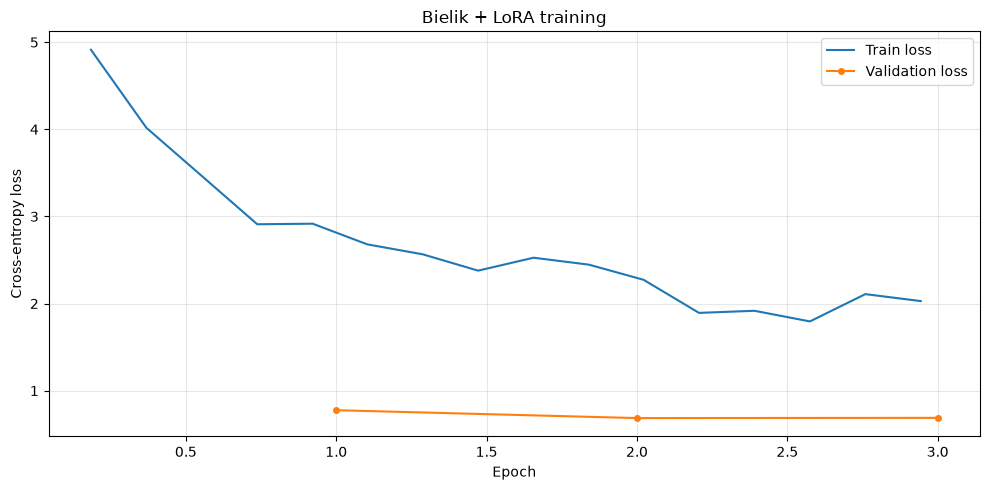

In [171]:
history_pretrained = trainer_pretrained.state.log_history
plot_training_history(history_pretrained, "Bielik + LoRA training")


Much lower val loss might be a result of dropout being active in the model during training, which is not applied during evaluation.

Test loss:     0.7135
Test accuracy: 69.06%
Test macro F1: 0.6798
Test encoding + inference time: 7.105 s
Test throughput: 76.4 examples/s


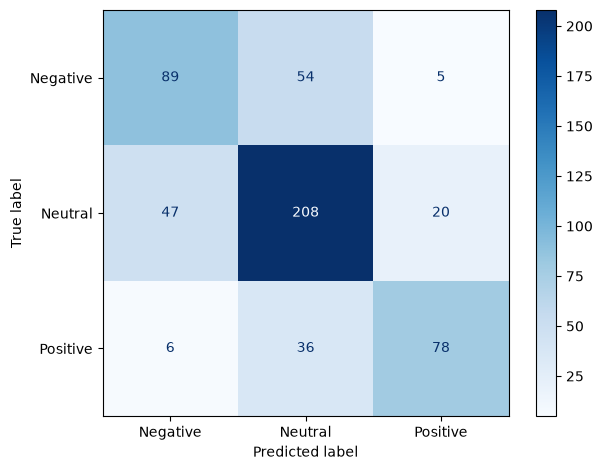

In [172]:
pretrained_results = test_model(trainer_pretrained, ds["test"])


### Example predictions

In [173]:
example_predictions = pd.DataFrame(
    pretrained_results["probabilities"][:6],
    columns=[classes[label] for label in pretrained_results["probability_class_ids"]],
)
example_predictions.insert(0, "Text", list(ds["test"]["text"][:6]))
example_predictions.insert(1, "True class", [classes[label] for label in ds["test"]["labels"][:6]])
example_predictions.insert(2, "Predicted class", pretrained_results["predicted_classes"][:6])
with pd.option_context("display.max_colwidth", None):
    display(example_predictions.round(2))


,Text,True class,Predicted class,Negative,Neutral,Positive
0,"-Wiedziałeś o tym, że Chopin odkrył poruszanie się słońca wokół Ziemii? -Co to za sritititi.",Negative,Neutral,0.18,0.79,0.03
1,- masz malego - twój stary,Negative,Neutral,0.11,0.86,0.03
2,"- Jesteś Sigma ? - Nie, jestem Ypsilon.",Neutral,Neutral,0.09,0.87,0.04
3,"- Mordo ale śmierdzisz -Ta, właśnie idę zwodować jajo",Neutral,Neutral,0.22,0.77,0.02
4,"Ludzie którzy nie rozumieją contentu Marcel to albo debile, albo boomerzy.",Negative,Negative,0.95,0.05,0.00
5,"U mnie w podstawówce to palarnia była dosłownie przy drugim wejściu do szkoły, nauczyciele widzieli, nic sobie z tego nie robili (patola straszna).",Negative,Negative,0.89,0.11,0.00


The Bielik + LoRA test result is 69% accuracy and 0.68 F1. This shows great improvement of the model compared to our model trained from scratch. We benefit from the massive amount of data used to train the Bielik model for next token prediction task.

In [174]:
training_time_summary = pd.DataFrame.from_dict(training_times, orient="index")
display(training_time_summary)


,training_total_s,epochs,training_mean_epoch_s
Scratch,34.7902,15.0,2.319347
Bielik + LoRA,416.9340,3.0,138.978000


In [175]:
del trainer_pretrained, model_pretrained_lora, model_pretrained
del collator_pretrained, tokenized_pretrained, tokenizer_pretrained
free_memory()

# 3. Zero-shot

I also use the original Bielik model as the "zero-shot" method. I load a fresh model with `AutoModelForCausalLM`,

The Polish prompt asks for Negative, Neutral, or Positive sentiment. It contains the text and the three possible label words, but no labelled examples.

In [176]:
from transformers import AutoModelForCausalLM

tokenizer_zero_shot = AutoTokenizer.from_pretrained(MODEL_NAME)
model_zero_shot = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

In [177]:
tokenizer_zero_shot.pad_token = tokenizer_zero_shot.eos_token
tokenizer_zero_shot.padding_side = "right"
model_zero_shot.config.pad_token_id = tokenizer_zero_shot.pad_token_id


In [178]:
POSITIVE_TOKEN="pozytywny"
NEUTRAL_TOKEN="neutralny"
NEGATIVE_TOKEN="negatywny"

classes_pl = {
    0: NEGATIVE_TOKEN,
    1: NEUTRAL_TOKEN,
    2: POSITIVE_TOKEN
}

In [179]:
class_token_ids = {
    tokenizer_zero_shot.encode(v, add_special_tokens=False)[0]: k
    for k, v in classes_pl.items()
}

class_token_ids

{22068: 0, 10994: 1, 19089: 2}

In [180]:
zero_shot_prompt = f"""
Określ sentyment poniższego tekstu.
Możliwe odpowiedzi: {NEGATIVE_TOKEN}, {NEUTRAL_TOKEN}, {POSITIVE_TOKEN}.

Tekst: {{text}}
Sentyment:
""".strip()

I classify each prompt with one model pass. I read the logits at the last non-padding position and keep only three class indicators - those must be encoded as unique tokens.

I choose the class with the largest selected logit. Softmax converts the three selected logits into probabilities.

This method restricts the decision to the three labels.

In [181]:
from tqdm import tqdm


@torch.inference_mode()
def predict_zero_shot_logits(model, tokenizer, texts, batch_size=INFERENCE_BATCH_SIZE):
    model.eval()
    token_ids = sorted(class_token_ids, key=class_token_ids.get)
    all_logits = []

    for start in tqdm(range(0, len(texts), batch_size), desc="Zero-shot"):
        batch = texts[start:start + batch_size]
        prompts = [zero_shot_prompt.format(text=text) for text in batch]
        inputs = tokenizer(prompts, padding=True, return_tensors="pt").to(model.device)

        outputs = model(**inputs, use_cache=False)
        last_positions = inputs["attention_mask"].sum(dim=1) - 1
        rows = torch.arange(len(batch), device=model.device)
        # Keep only the next-token logits for our three class indicators.
        class_logits = outputs.logits[rows, last_positions][:, token_ids]
        all_logits.append(class_logits.float().cpu())
        del outputs

    return torch.cat(all_logits)


def predict_zero_shot(model, tokenizer, texts, batch_size=INFERENCE_BATCH_SIZE):
    class_logits = predict_zero_shot_logits(model, tokenizer, texts, batch_size)
    # Normalize over the selected class tokens only, in class ID order.
    # T = 1: no temperature calibration is applied to Bielik.
    probabilities = torch.softmax(class_logits, dim=-1).numpy()
    class_ids = np.asarray(sorted(class_token_ids.values()))
    predictions = class_ids[probabilities.argmax(axis=-1)]
    return predictions, probabilities


In [182]:
def test_zero_shot(model, tokenizer, data, batch_size=INFERENCE_BATCH_SIZE):
    texts = list(data["text"])
    if model.device.type == "cuda":
        torch.cuda.synchronize(model.device)
    start = perf_counter()
    y_pred, probabilities = predict_zero_shot(model, tokenizer, texts, batch_size=batch_size)
    if model.device.type == "cuda":
        torch.cuda.synchronize(model.device)
    inference_time = perf_counter() - start
    y_true = np.asarray(data["labels"])
    labels = list(classes)

    metrics = {
        "inference_time_seconds": inference_time,
        "inference_samples_per_second": len(data) / inference_time,
        "probabilities": probabilities,
        "probability_class_ids": sorted(class_token_ids.values()),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels),
        "predictions": y_pred,
        "predicted_classes": [classes[label] for label in y_pred],
    }

    print(f"Test accuracy: {metrics['accuracy']:.2%}")
    print(f"Test macro F1: {metrics['macro_f1']:.4f}")
    print(f"Test encoding + inference time: {metrics['inference_time_seconds']:.3f} s")
    print(f"Test throughput: {metrics['inference_samples_per_second']:.1f} examples/s")

    ConfusionMatrixDisplay(
        confusion_matrix=metrics["confusion_matrix"],
        display_labels=[classes[label] for label in labels],
    ).plot(cmap="Blues", values_format="d")
    plt.tight_layout()
    plt.show()

    return metrics


Zero-shot: 100%|██████████| 68/68 [00:09<00:00,  7.55it/s]

Test accuracy: 62.98%
Test macro F1: 0.5911
Test encoding + inference time: 9.009 s
Test throughput: 60.3 examples/s


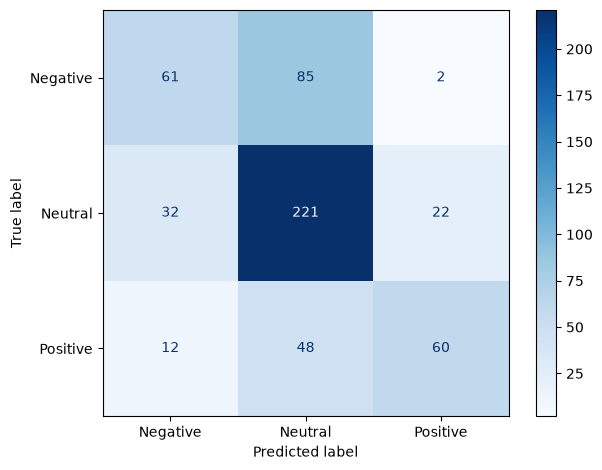

In [183]:
zero_shot_results = test_zero_shot(
    model_zero_shot,
    tokenizer_zero_shot,
    ds["test"],
    batch_size=INFERENCE_BATCH_SIZE,
)


The Bielik as a zero-shot model gives a result of 63% accuracy and 0.59 macro F1. This exceeds our custom model, but stills doesn't beat fine-tuned model.

### Example predictions

In [184]:
example_predictions = pd.DataFrame(
    zero_shot_results["probabilities"][:6],
    columns=[classes[label] for label in zero_shot_results["probability_class_ids"]],
)
example_predictions.insert(0, "Text", list(ds["test"]["text"][:6]))
example_predictions.insert(1, "True class", [classes[label] for label in ds["test"]["labels"][:6]])
example_predictions.insert(2, "Predicted class", zero_shot_results["predicted_classes"][:6])
with pd.option_context("display.max_colwidth", None):
    display(example_predictions.round(2))


,Text,True class,Predicted class,Negative,Neutral,Positive
0,"-Wiedziałeś o tym, że Chopin odkrył poruszanie się słońca wokół Ziemii? -Co to za sritititi.",Negative,Neutral,0.17,0.74,0.09
1,- masz malego - twój stary,Negative,Neutral,0.16,0.61,0.22
2,"- Jesteś Sigma ? - Nie, jestem Ypsilon.",Neutral,Neutral,0.14,0.74,0.12
3,"- Mordo ale śmierdzisz -Ta, właśnie idę zwodować jajo",Neutral,Neutral,0.27,0.51,0.21
4,"Ludzie którzy nie rozumieją contentu Marcel to albo debile, albo boomerzy.",Negative,Negative,0.36,0.36,0.28
5,"U mnie w podstawówce to palarnia była dosłownie przy drugim wejściu do szkoły, nauczyciele widzieli, nic sobie z tego nie robili (patola straszna).",Negative,Negative,0.43,0.34,0.23


In [185]:
del model_zero_shot, tokenizer_zero_shot
free_memory()


# 4. Comparison

All three methods were ranked using the same test set - around 500 samples. Each method uses a batch size of 8, and each timer includes text encoding and prediction.

As a comparison, in the table below I have added naive baseline which predicts the Neutral class for all texts.

In [188]:
comparison = pd.DataFrame([
    {
        "Model": name,
        "accuracy": results["accuracy"],
        "macro_f1": results["macro_f1"],
        "training_total_s": training_times[name]["training_total_s"] if name != "Bielik zero-shot" else np.nan,
        "training_mean_epoch_s": training_times[name]["training_mean_epoch_s"] if name != "Bielik zero-shot" else np.nan,
        "encoding_inference_total_s": results["inference_time_seconds"],
        "encoding_inference_examples_per_second": results["inference_samples_per_second"],
    }
    for name, results in [
        ("Scratch", scratch_results),
        ("Bielik + LoRA", pretrained_results),
        ("Bielik zero-shot", zero_shot_results),
    ]
]).set_index("Model")
# Naive baseline: always predict Neutral (class 1).
baseline_predictions = np.full(len(ds["test"]), 1, dtype=int)
comparison.loc["Neutral baseline"] = {
    "accuracy": accuracy_score(ds["test"]["labels"], baseline_predictions),
    "macro_f1": f1_score(
        ds["test"]["labels"],
        baseline_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0,
    ),
    "training_total_s": 0.0,
    "training_mean_epoch_s": np.nan,
    "encoding_inference_total_s": np.nan,
    "encoding_inference_examples_per_second": np.nan,
}
display(comparison.round(2))


,accuracy,macro_f1,training_total_s,training_mean_epoch_s,encoding_inference_total_s,encoding_inference_examples_per_second
Model,,,,,,
Scratch,0.54,0.48,34.79,2.32,0.22,2513.16
Bielik + LoRA,0.69,0.68,416.93,138.98,7.11,76.42
Bielik zero-shot,0.63,0.59,NaN,NaN,9.01,60.27
Neutral baseline,0.51,0.22,0.00,NaN,NaN,NaN


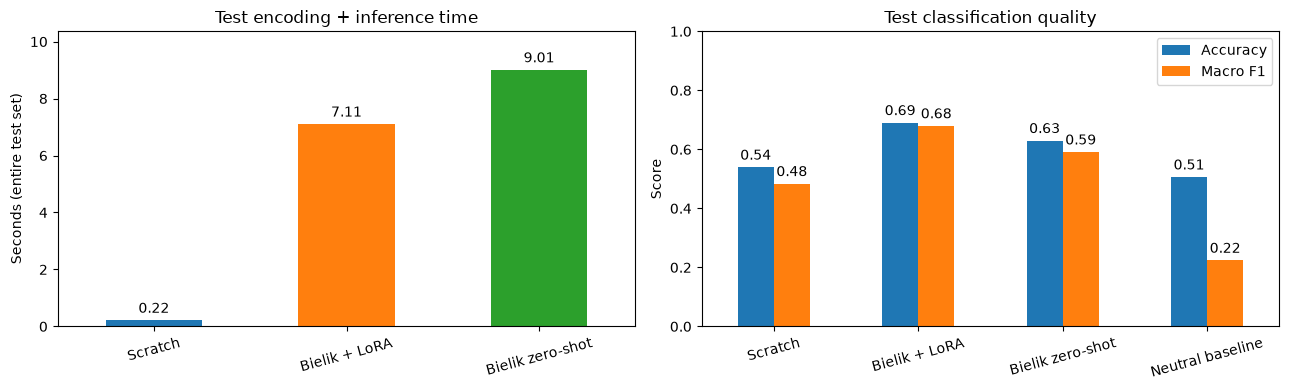

In [190]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))

comparison.drop(index="Neutral baseline")["encoding_inference_total_s"].plot.bar(
    ax=axs[0], rot=15, color=["tab:blue", "tab:orange", "tab:green"],
)
axs[0].set_title("Test encoding + inference time")
axs[0].set_ylabel("Seconds (entire test set)")
axs[0].set_xlabel("")
axs[0].bar_label(axs[0].containers[0], fmt="%.2f", padding=3)
axs[0].margins(y=0.15)

comparison[["accuracy", "macro_f1"]].plot.bar(ax=axs[1], rot=15)
axs[1].set_title("Test classification quality")
axs[1].set_ylabel("Score")
axs[1].set_xlabel("")
axs[1].set_ylim(0, 1)
axs[1].legend(["Accuracy", "Macro F1"])
for bars in axs[1].containers:
    axs[1].bar_label(bars, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()


The results of the comparison are rather clear:

1. Finetuning pretrained model gives the best result, and adding specialized classification head improves the inference time over the base model.
2. Zero-shot prediction gives us an idea, how much information the pretrained model already contains relevant to the sentiment classification task.
3. Training a custom Transformer model requires a lot of data and specializing it in given tasks will rather require transfer learning and pretraining it on our own, but the performance of small model will be unbeatable by Large Language Models.

In an environment with constrained resources, training a custom Transformer will probably be a preferred approach, because we might be able to achieve reasonable performance. Using zero-shot prediction, might be favorable where we want quick results without task-specific training - fine-tuning, event with LoRA, still requires resources and might be costly, while with zero-shot, we just pay with the longer inference time and with larger models, results might still be competitive.

My comparison might be unfair, because we have compared models with different vocabulary sizes and magnitudes of parameter counts and pretraining costs.